# What we built and what it did

TabICL v2's released table stages, fine-tuned, with an image side trained from scratch on generated tables where every row also carries a real photo. The photo is encoded by frozen DINOv2 (block 4 patch tokens); the image side reads it against the 32 nearest context photos and their labels. This notebook shows one training task, walks one batch through the model, and plots the results that decided things. Numbers come from the files in `results/`.

In [1]:
import os, sys, json
os.chdir(next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.exists(os.path.join(p, "table_image_icl"))))
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

OUT = "assets/results"
os.makedirs(OUT, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

def record(run, name):
    return json.load(open(f"results/{run}/{name}"))

GROUPED = ["CBIS-DDSM", "CheXpert", "Mango Mass", "PAD-UFES-20", "SoCal Houses"]   # scored with each patient, fruit or listing on one side of the split, see section 4
VALIDATION = ["CBIS-DDSM", "HAM10000", "CheXpert", "Mango Mass"]
NO_HARM = ["PAD-UFES-20", "SoCal Houses", "DVM-Car"]

def benchmark(run, suffix="", which="validation"):
    """The real-data records of one set at one context size (suffix "" or "-contextN"): the benchmark's row-wise split
    for the datasets without groups, the grouped split (the -grouped records) for those with groups."""
    base = "multabench" if which == "validation" else "multabench-no-harm"
    path = f"results/{run}/{base}{suffix}.json"
    if not os.path.exists(path):
        return {}
    m = {ds: d for ds, d in json.load(open(path))["datasets"].items() if ds not in GROUPED}
    grouped = f"results/{run}/{base}-grouped{suffix}.json"
    return m | json.load(open(grouped))["datasets"] if os.path.exists(grouped) else m

## 1. One training task

A table from TabICL v2's prior. One column is hidden and shown only through the photo: its value picks the photo's class. So the photo carries information the table lost, and the model can only get it back by reading the photo.

columns kept: 7 | hidden column values: [-1.08  2.47  0.18 -0.55  0.41  0.18] | bins: [0 2 2 1 2 2]


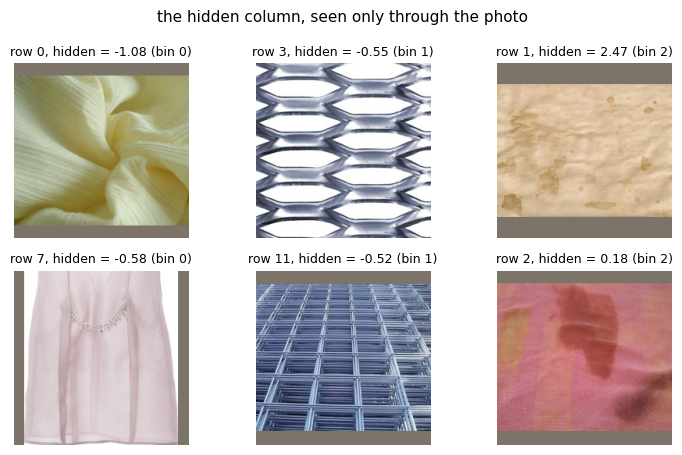

In [2]:
from table_image_icl.collections import load_collection
from table_image_icl.tasks import TaskConfig, task_batches

collections = {name: load_collection(name, max_images=600) for name in ["eurosat", "dtd"]}
cfg = TaskConfig(batch_size=2, rows=(40, 56), features=(4, 8), max_classes=4, max_bins=3, image_as_label_share=0.0)
batch = next(task_batches(cfg, collections, seed=1))
t = 0
c = collections[batch.collection[t]]
print("columns kept:", int(batch.n_columns[t]), "| hidden column values:", batch.hidden[t, :6].numpy().round(2), "| bins:", batch.bins[t, :6].numpy())

fig, axes = plt.subplots(2, 3, figsize=(7.5, 4.6))
for k in range(3):
    for i, r in enumerate(np.where(batch.bins[t].numpy() == k)[0][:2]):
        idx = int(batch.image_index[t, r])
        axes[i, k].imshow(c["images"][idx]); axes[i, k].axis("off")
        axes[i, k].set_title(f"row {r}, hidden = {batch.hidden[t, r]:.2f} (bin {k})", fontsize=9)
fig.suptitle("the hidden column, seen only through the photo", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/task.png", dpi=160, bbox_inches="tight")

## 2. The model, one batch at a time

Four stages; three are TabICL v2's, pretrained on about 82M tables and fine-tuned here at a small learning rate. Column stage: each column's cells attend to each other, so a cell knows its column's distribution. Image side (ours, trained from scratch): the frozen DINOv2 patches of a row go through a small encoder, then a labelled read where they attend to the patches of the 32 nearest context photos and read their labels. Row stage: a row's cells and its patches attend to each other and are pooled into one token. In-context stage: rows attend to rows, test rows read the context labels and score the classes. The released weights are loaded from `checkpoints/block4`.

In [3]:
from table_image_icl.model import load_run
from table_image_icl.tables import contiguous_codes, prepare_table
from table_image_icl.tasks import Tasks
from table_image_icl.inputs import inputs_for

model, config = load_run("checkpoints/block4")
for name, module in model.named_children():
    print(f"{name:13s} {sum(p.numel() for p in module.parameters()) / 1e6:6.2f}M", "(TabICL v2, pretrained)" if name == "table" else "(ours)")

tasks = Tasks(cfg, collections, ["eurosat"], ["dtd"], inputs_for("dino", "cpu", block=config["dino_block"]))
inputs = tasks.inputs(batch, "cpu", "image")
n_context = inputs["y_context"].shape[1]
codes, slots = contiguous_codes(inputs["y_context"])                                # TabICL wants classes numbered 0..k-1
with torch.no_grad():
    cells = model.table.col_embedder._train_forward(prepare_table(inputs["x"], n_context), codes, None, False); print("column stage ", tuple(cells.shape))
    patches = model.photo_tokens(inputs["images"], inputs["y_context"]);                                         print("image side   ", tuple(patches.shape))
    rows = model.table.row_interactor._train_forward(torch.cat([cells, patches], 2), None);                      print("row stage    ", tuple(rows.shape))
    logits = model.table.icl_predictor._icl_predictions(rows, codes)[:, n_context:];                             print("in-context   ", tuple(logits.shape))
    log_probs = model(inputs["x"], inputs["y_context"], images=inputs["images"]);                                print("output       ", tuple(log_probs.shape), "(log-probabilities over the label slots)")
acc = (log_probs[t].argmax(-1) == batch.y_test[t]).float().mean().item()
print(f"accuracy on this task's test rows: {acc:.2f}")

table          27.55M (TabICL v2, pretrained)
embed           0.10M (ours)
encoder         0.56M (ours)
read            0.27M (ours)


Using cache found in /Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


column stage  (2, 45, 11, 128)


image side    (2, 45, 256, 128)
row stage     (2, 45, 512)
in-context    (2, 5, 10)


output        (2, 5, 10) (log-probabilities over the label slots)
accuracy on this task's test rows: 1.00


## 3. Did it learn to use the photo?

The model is scored on 400 fixed tasks whose photos come from collections it never trained on, shown four ways: the table alone, the table with each row's photo, the table with the hidden column handed back as a plain column, and the table with each row given another row's photo. Test accuracy, averaged over the tasks. The last view is a control: if the model only liked having extra tokens, it would score as well there as with the right photo.

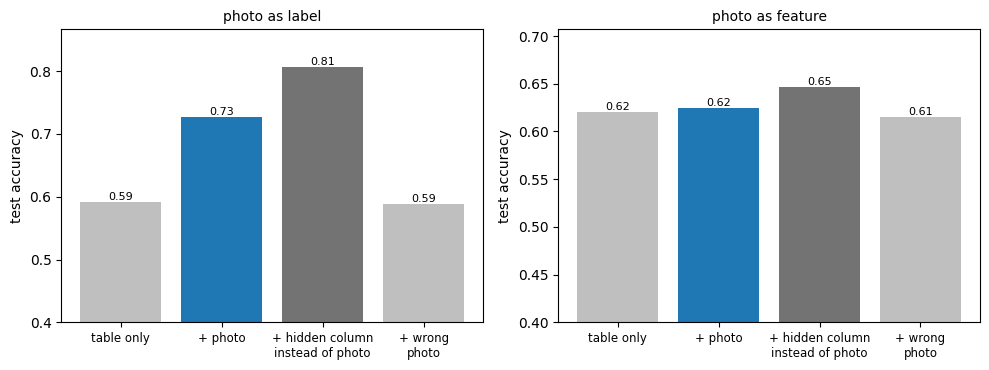

In [4]:
e = record("block4", "evaluation.json")["by_role"]
views = ["no image", "image", "column visible", "images shuffled"]
names = ["table only", "+ photo", "+ hidden column\ninstead of photo", "+ wrong\nphoto"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, role in zip(axes, ["label", "feature"]):
    acc = [e[role]["views"][v]["accuracy"] for v in views]
    bars = ax.bar(names, acc, color=["0.75", "C0", "0.45", "0.75"])
    for b, a in zip(bars, acc):
        ax.text(b.get_x() + b.get_width() / 2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"photo as {role}", fontsize=10); ax.set_ylabel("test accuracy"); ax.tick_params(axis="x", labelsize=8.5)
    ax.set_ylim(0.4, max(acc) + 0.06)
fig.tight_layout(); fig.savefig(f"{OUT}/views.png", dpi=160, bbox_inches="tight")

The photo lifts accuracy and the wrong photo does not, so the model reads the photo. A photo that stands in for the label is read well, most of the way to seeing the column itself; a photo that stands in for a feature barely helps.

## 4. Real data

MulTaBench's image-table datasets, 256 labelled rows as context, no training on the data. The benchmark admits a dataset to its core set when the table plus frozen image features beats either alone *and* fine-tuning the encoder on the target helps. Where tuning helps, the photo carries information that frozen features miss, and that is the room an in-context read of the photo can use, so the model is judged on three core datasets with large tuning gains, CBIS-DDSM (mammography, 4 classes), CheXpert (chest X-ray, 3 classes) and Mango Mass (fruit photo, mass regression), plus HAM10000 (dermoscopy, 7 classes) from the benchmark's extended slice. The reference is TabPFN v2 fed the table plus a PCA of frozen DINOv2 features: the same photo information, a strong table learner.

**The split.** MulTaBench splits rows i.i.d. and says its splits are not audited for group structure. Read off the benchmark's own files, CBIS-DDSM rows are abnormalities of 892 patients (63% of test rows have another row of the same patient among the training rows), CheXpert rows are studies of 20,638 patients, and Mango Mass photographs each fruit twice. HAM10000 has one image per lesion. For the grouped datasets every number in this notebook comes from a split that keeps each patient or fruit on one side (`scripts/benchmark.py --grouped`, records `*-grouped*.json`); the benchmark's row-wise records are kept next to them.

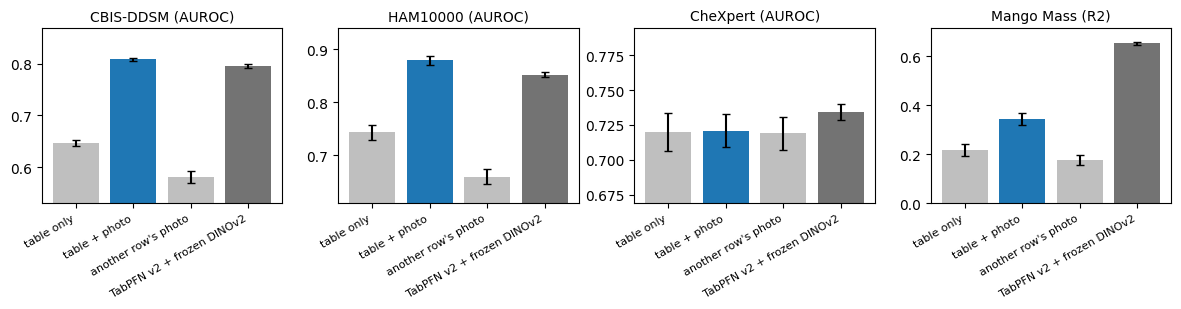

In [5]:
m = benchmark("block4")
keys = ["ours, table only", "ours, table + image", "ours, image of another row", "TabPFN v2, table + frozen DINOv2 PCA"]
names = ["table only", "table + photo", "another row's photo", "TabPFN v2 + frozen DINOv2"]

def real_data_figure(m, path):
    fig, axes = plt.subplots(1, len(m), figsize=(3 * len(m), 3.2))
    for ax, (ds, d) in zip(axes, m.items()):
        means = [d[k]["mean"] for k in keys]; ses = [d[k]["se"] for k in keys]
        ax.bar(range(4), means, yerr=ses, color=["0.75", "C0", "0.75", "0.45"], capsize=3)
        ax.set_xticks(range(4)); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
        ax.set_title(f"{ds} ({d['metric']})", fontsize=10)
        lo = min(means) - 0.05 if d["metric"] == "AUROC" else min(0, min(means) - 0.05)
        ax.set_ylim(lo, max(means) + 0.06)
    fig.tight_layout(); fig.savefig(path, dpi=160, bbox_inches="tight")
real_data_figure({ds: m[ds] for ds in VALIDATION}, f"{OUT}/realdata.png")

On CBIS-DDSM the photo adds 0.16 AUROC and on HAM10000 0.14, with no training on the data, and the model is ahead of the frozen-feature reference on both. On CheXpert no method's photo adds anything. On Mango Mass the photo adds 0.12 R² for this arm but the reference is far ahead; the from-scratch arm (section 5) reads this photo much better, 0.73 against the reference's 0.65 on the fruit-grouped split.

## 5. The ablation that mattered: which DINOv2 block

Every arm shares the table side (TabICL v2's stages, learning rate 1e-5) and the image-side setting (top-k 32 reads, 25k steps, seed 0). Only what the image side receives differs: frozen DINOv2 patch tokens from block 4, 8 or 12, DINOv2's final CLS and register tokens, or raw pixels through one linear layer trained from scratch (grey).

Deeper, more semantic DINOv2 features win on generated tasks and lose on the real data; the ordering on the medical sets is the reverse of the ordering on generated photos. The from-scratch arm is the extreme case: the weakest on generated tasks and the best on HAM10000, CheXpert and Mango Mass, behind block 4 only on CBIS-DDSM. The reference lines on the real-data panels are TabPFN v2 on the table alone (dashed) and TabPFN v2 on the table plus 30 PCA components of frozen DINOv2 final features (dotted), both at the same 256 context rows.

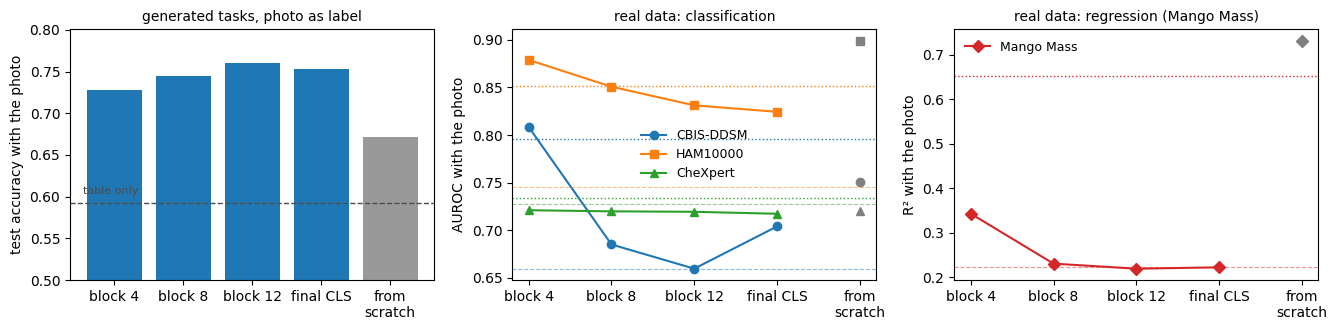

In [6]:
arms = {"block 4": "block4", "block 8": "block8", "block 12": "block12", "final CLS": "cls"}
scratch = {"from\nscratch": "pixels"}
KEY = "ours, table + image"
def scores(runs):
    photo = [record(r, "evaluation.json")["by_role"]["label"]["views"]["image"]["accuracy"] for r in runs.values()]
    real = {ds: [benchmark(r)[ds][KEY]["mean"] for r in runs.values()] for ds in VALIDATION}
    return photo, real
with_photo, real = scores(arms)
scratch_photo, scratch_real = scores(scratch)
table_only = np.mean([record(r, "evaluation.json")["by_role"]["label"]["views"]["no image"]["accuracy"] for r in (arms | scratch).values()])
ref = benchmark("block4")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4))
axes[0].bar(list(arms), with_photo, color="C0"); axes[0].bar(list(scratch), scratch_photo, color="0.6")
axes[0].axhline(table_only, color="0.3", ls="--", lw=1); axes[0].text(-0.45, table_only + 0.01, "table only", fontsize=8, ha="left", color="0.3")
axes[0].set_ylim(0.5, max(with_photo) + 0.04); axes[0].set_ylabel("test accuracy with the photo"); axes[0].set_title("generated tasks, photo as label", fontsize=10)
for ds, mk, c in [("CBIS-DDSM", "o", "C0"), ("HAM10000", "s", "C1"), ("CheXpert", "^", "C2")]:
    axes[1].plot(list(arms), real[ds], mk + "-", color=c, label=ds); axes[1].plot(list(scratch), scratch_real[ds], mk, color="0.5")
    axes[1].axhline(ref[ds]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color=c, ls=":", lw=1); axes[1].axhline(ref[ds]["TabPFN v2, table only"]["mean"], color=c, ls="--", lw=0.8, alpha=0.5)
axes[1].set_ylabel("AUROC with the photo"); axes[1].legend(frameon=False, fontsize=9); axes[1].set_title("real data: classification", fontsize=10)
for ds, mk, c in [("Mango Mass", "D", "C3")]:
    axes[2].plot(list(arms), real[ds], mk + "-", color=c, label=ds); axes[2].plot(list(scratch), scratch_real[ds], mk, color="0.5")
    axes[2].axhline(ref[ds]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color=c, ls=":", lw=1); axes[2].axhline(ref[ds]["TabPFN v2, table only"]["mean"], color=c, ls="--", lw=0.8, alpha=0.5)
axes[2].set_ylabel("R² with the photo"); axes[2].legend(frameon=False, fontsize=9); axes[2].set_title("real data: regression (Mango Mass)", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/depth.png", dpi=160, bbox_inches="tight")

## 6. More context rows, no retraining

The model was trained on tables of 64 to 256 rows. Scoring it with more context rows costs nothing but inference: the source cap of the labelled read is raised to match, and the in-context stage extrapolates. The frozen reference gets the same rows each time. MulTaBench caps the training side of a split at 10,000 rows and most datasets have fewer, so each line stops where its data stops (CBIS-DDSM at about 1,100 rows, HAM10000 at 4,980, Mango Mass at 364). The lines are the model with frozen block-4 tokens, with and without the photo, and the from-scratch arm with the photo.

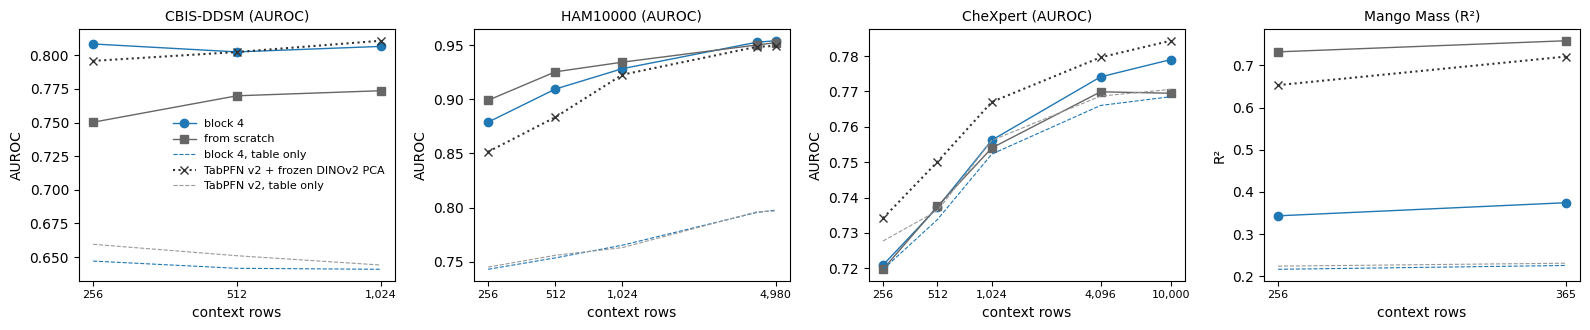

In [7]:
lines = {"block 4": ("block4", "C0", "o", KEY), "from scratch": ("pixels", "0.4", "s", KEY), "block 4, table only": ("block4", "C0", "", "ours, table only")}
SIZES = [256, 512, 1024, 4096, 10000]
def sweep(run, ds, key=KEY, which="validation"):
    points = {}
    for n in SIZES:
        d = benchmark(run, "" if n == 256 else f"-context{n}", which).get(ds)
        if d is not None:                                        # a grouped dataset has no point where its grouped record stops
            points[d["context_rows"]] = d[key]["mean"]
    return sorted(points.items())

def context_figure(datasets, which, path):
    fig, axes = plt.subplots(1, len(datasets), figsize=(4 * len(datasets), 3.4))
    for ax, ds in zip(axes, datasets):
        for name, (run, color, mk, key) in lines.items():
            pts = sweep(run, ds, key, which)
            ax.plot(*zip(*pts), mk + ("-" if mk else "--"), color=color, lw=1 if mk else 0.8, label=name)
        pts = sweep("block4", ds, "TabPFN v2, table + frozen DINOv2 PCA", which); ax.plot(*zip(*pts), "x:", color="0.2", label="TabPFN v2 + frozen DINOv2 PCA")
        pts = sweep("block4", ds, "TabPFN v2, table only", which); ax.plot(*zip(*pts), "--", color="0.6", lw=0.8, label="TabPFN v2, table only")
        metric = benchmark("block4", which=which)[ds]["metric"].replace("R2", "R²")
        ax.set_xscale("log"); ax.set_xlabel("context rows"); ax.set_title(f"{ds} ({metric})", fontsize=10); ax.set_ylabel(metric)
        shown = sorted({x for run, _, _, _ in lines.values() for x, _ in sweep(run, ds, which=which)}); shown = [x for i, x in enumerate(shown) if i == len(shown) - 1 or shown[i + 1] > 1.3 * x]; ax.set_xticks(shown); ax.set_xticklabels([f"{x:,}" for x in shown], fontsize=8); ax.minorticks_off()
    axes[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=160, bbox_inches="tight")
context_figure(VALIDATION, "validation", f"{OUT}/context.png")

Both arms extrapolate to 4 to 40 times their training context and keep improving. On CBIS-DDSM and HAM10000 the lead over the frozen reference is largest at 256 to 1,024 rows and the methods meet at the largest contexts, where the table-only view and TabPFN v2 meet too; on CheXpert the reference stays about 0.01 ahead at every size and no method's photo adds much; on Mango Mass the from-scratch arm stays ahead of the reference at both sizes the data allows. The photo's advantage for in-context reading is a few-shot advantage.

## 7. Where frozen features already suffice

Three datasets from the benchmark's extended slice, where the benchmark found that fine-tuning the encoder does not help: PAD-UFES-20 (smartphone lesion photo and 22 clinical features, 6 classes), SoCal Houses (listing photo and 6 features, price) and DVM-Car (car photo and 16 listing features, price). Here the frozen baseline is at its ceiling and an in-context read of the photo has nothing to win, so the question is only whether the model keeps up. PAD-UFES-20 is scored with each patient on one side of the split and SoCal Houses with each listing on one side (the benchmark's row-wise split lists 26% of SoCal test rows' houses, with the identical price, among the training rows; DVM-Car has one photo per advert).

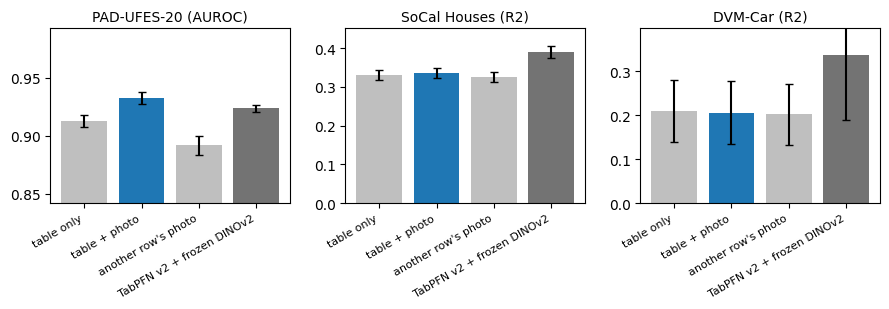

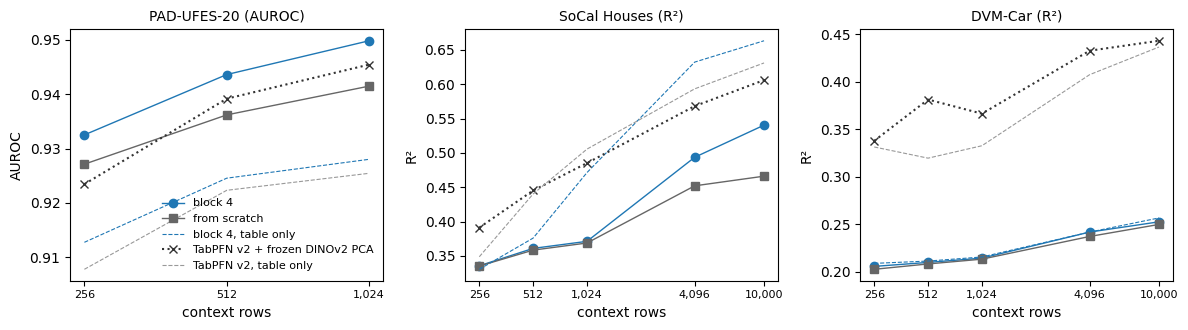

In [8]:
m = benchmark("block4", which="no-harm")
real_data_figure({ds: m[ds] for ds in NO_HARM}, f"{OUT}/noharm.png")
context_figure(NO_HARM, "no-harm", f"{OUT}/noharm_context.png")

On PAD-UFES-20 the model keeps up and slightly leads at every context size (0.933 against 0.923 at 256 rows, 0.950 against 0.945 at 1,024). On the two regression tables the reference is ahead with or without the photo: on SoCal Houses the table-only view improves to 0.66 R² at 10,000 rows, above TabPFN v2, but the photo starts to cost from about 1,000 rows on and costs 0.12 at the end, and the reference loses from its PCA columns there as well, so a house photo is noise for the price once the table is large. On DVM-Car the photo never matters for any method and the table-only view trails TabPFN v2 by 0.18 at every size, which is the 10-bin regression head, not the photo.

## 8. The five arms, in one table

The numbers behind sections 5 and 7. Test accuracy on the 400 generated tasks with the photo (and, for reference, without it), then the validation sets and the no-harm sets with the photo.

In [9]:
rows = []
for name, r in (arms | scratch).items():
    e = record(r, "evaluation.json")["by_role"]; m = benchmark(r) | benchmark(r, which="no-harm")
    rows.append([name.replace("\n", " "), round(e["label"]["views"]["no image"]["accuracy"], 3), round(e["label"]["views"]["image"]["accuracy"], 3),
                 round(e["feature"]["views"]["image"]["accuracy"], 3)] + [round(m[ds][KEY]["mean"], 3) for ds in VALIDATION + NO_HARM])
pd.DataFrame(rows, columns=["arm", "table only", "with photo (as label)", "with photo (as feature)", "CBIS AUROC", "HAM AUROC", "CheXpert AUROC", "Mango R²", "PAD AUROC", "SoCal R²", "DVM-Car R²"]).set_index("arm")

,table only,with photo (as label),with photo (as feature),CBIS AUROC,HAM AUROC,CheXpert AUROC,Mango R²,PAD AUROC,SoCal R²,DVM-Car R²
arm,,,,,,,,,,
block 4,0.591,0.728,0.624,0.808,0.879,0.721,0.343,0.933,0.336,0.206
block 8,0.591,0.745,0.632,0.685,0.851,0.720,0.231,0.924,0.335,0.205
block 12,0.594,0.761,0.631,0.659,0.831,0.719,0.220,0.917,0.335,0.213
final CLS,0.593,0.753,0.635,0.704,0.824,0.717,0.223,0.917,0.336,0.214
from scratch,0.595,0.672,0.621,0.750,0.899,0.720,0.732,0.927,0.335,0.203


What we take from this: the model learns to read a photo in context, on CBIS-DDSM and HAM10000 it is ahead of frozen features plus TabPFN v2 at 256 context rows, it keeps up where frozen features suffice, and real-data numbers are the ones to trust, since gains on generated tasks (deeper blocks) did not carry over. The in-context stage inherited from TabICL v2 is what lets the model use far more context rows than it was trained on.